In [6]:
import os
import sys
import re
import subprocess
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

PROJECT_DIR = "/root/autodl-tmp/train"
DATA_DIR = "/root/autodl-tmp/medical_data/hemorrhage_vs_tumor_brain_only"

TEST_DATA_DIR = (
    "/root/autodl-tmp/medical_data/"
    "hemorrhage_vs_tumor"
)

DATASET_NAME = "HemorrhageVsTumor"
NUM_CLASSES = 2

EPOCHS = 30
BATCH_SIZE = 16
N_FEATURE = BATCH_SIZE
GPU = 0

# StableNet开启
EPOCHP = 0

SEEDS = [1, 3, 7, 21, 42]

os.chdir(PROJECT_DIR)

In [7]:
all_seed_results = []
all_seed_outputs = {}

for run_index, seed in enumerate(SEEDS, start=1):
    log_base = (
        f"/root/autodl-tmp/train/"
        f"results_5seeds/seed_{seed}"
    )

    cmd = [
        sys.executable,
        "-u",
        "main_stablenet.py",

        "-data", DATA_DIR,
        "--test-data", TEST_DATA_DIR,
        "--dataset", DATASET_NAME,
        "--classes_num", str(NUM_CLASSES),

        "--gpu", str(GPU),
        "--batch-size", str(BATCH_SIZE),
        "--n_feature", str(N_FEATURE),
        "--workers", "4",

        "--epochs", str(EPOCHS),
        "--epochp", str(EPOCHP),
        "--seed", str(seed),

        "--lr", "0.001",
        "--wd", "0.0001",
        "--cos", "1",

        "--lrbl", "1",
        "--lambdap", "70",
        "--epochb", "20",

        "--log_base", log_base,
    ]

    print()
    print("=" * 65)
    print(f"第 {run_index}/{len(SEEDS)} 次实验，随机种子：{seed}")
    print("=" * 65)

    process = subprocess.Popen(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    lines = []
    evaluation_index = 0

    for line in process.stdout:
        lines.append(line)
        stripped = line.strip()

        if "* Acc@1" in line:
            epoch = evaluation_index // 2 + 1
            phase = (
                "Validation"
                if evaluation_index % 2 == 0
                else "Test"
            )

            print(
                f"Seed {seed:2d} | "
                f"Epoch {epoch:02d} | "
                f"{phase:10s} | {stripped}"
            )

            evaluation_index += 1

    process.wait()
    raw_output = "".join(lines)
    all_seed_outputs[seed] = raw_output

    if process.returncode != 0:
        print(f"\nSeed {seed} 训练失败")

        for line in lines[-60:]:
            print(line, end="")

        continue

    # 同时兼容Acc@2和Acc@5
    matches = re.findall(
        r"\*\s+Acc@1\s+([-\d.]+)"
        r"\s+Acc@(?:2|5)\s+([-\d.]+)",
        raw_output
    )

    epoch_results = []

    for i in range(0, len(matches), 2):
        if i + 1 >= len(matches):
            break

        val_accuracy = float(matches[i][0])
        test_accuracy = float(matches[i + 1][0])

        epoch_results.append({
            "epoch": i // 2 + 1,
            "val_accuracy": val_accuracy,
            "test_accuracy": test_accuracy,
        })

    if not epoch_results:
        print("没有解析到准确率")
        continue

    # 只能根据验证集选择最佳epoch
    best = max(
        epoch_results,
        key=lambda item: item["val_accuracy"]
    )

    model_path = (
        Path(log_base) /
        DATASET_NAME /
        "model_best.pth.tar"
    )

    all_seed_results.append({
        "Seed": seed,
        "Best Epoch": best["epoch"],
        "Validation Accuracy": best["val_accuracy"],
        "Test Accuracy": best["test_accuracy"],
        "Model Path": str(model_path),
        "Model Exists": model_path.is_file(),
    })

    print(
        f"\nSeed {seed} 完成："
        f"最佳epoch={best['epoch']}，"
        f"验证={best['val_accuracy']:.2f}%，"
        f"测试={best['test_accuracy']:.2f}%"
    )


第 1/5 次实验，随机种子：1
Seed  1 | Epoch 01 | Validation | * Acc@1 50.000 Acc@5 100.000
Seed  1 | Epoch 01 | Test       | * Acc@1 57.576 Acc@5 100.000
Seed  1 | Epoch 02 | Validation | * Acc@1 96.667 Acc@5 100.000
Seed  1 | Epoch 02 | Test       | * Acc@1 66.667 Acc@5 100.000
Seed  1 | Epoch 03 | Validation | * Acc@1 86.667 Acc@5 100.000
Seed  1 | Epoch 03 | Test       | * Acc@1 96.970 Acc@5 100.000
Seed  1 | Epoch 04 | Validation | * Acc@1 90.000 Acc@5 100.000
Seed  1 | Epoch 04 | Test       | * Acc@1 84.848 Acc@5 100.000
Seed  1 | Epoch 05 | Validation | * Acc@1 96.667 Acc@5 100.000
Seed  1 | Epoch 05 | Test       | * Acc@1 78.788 Acc@5 100.000
Seed  1 | Epoch 06 | Validation | * Acc@1 100.000 Acc@5 100.000
Seed  1 | Epoch 06 | Test       | * Acc@1 63.636 Acc@5 100.000
Seed  1 | Epoch 07 | Validation | * Acc@1 100.000 Acc@5 100.000
Seed  1 | Epoch 07 | Test       | * Acc@1 63.636 Acc@5 100.000
Seed  1 | Epoch 08 | Validation | * Acc@1 100.000 Acc@5 100.000
Seed  1 | Epoch 08 | Test       | 

In [8]:
seed_df = pd.DataFrame(all_seed_results)

display(
    seed_df.style.format({
        "Validation Accuracy": "{:.2f}%",
        "Test Accuracy": "{:.2f}%"
    })
)

,Seed,Best Epoch,Validation Accuracy,Test Accuracy,Model Path,Model Exists
0,1,6,100.00%,63.64%,/root/autodl-tmp/train/results_5seeds/seed_1/HemorrhageVsTumor/model_best.pth.tar,True
1,3,5,100.00%,78.79%,/root/autodl-tmp/train/results_5seeds/seed_3/HemorrhageVsTumor/model_best.pth.tar,True
2,7,4,100.00%,84.85%,/root/autodl-tmp/train/results_5seeds/seed_7/HemorrhageVsTumor/model_best.pth.tar,True
3,21,3,100.00%,60.61%,/root/autodl-tmp/train/results_5seeds/seed_21/HemorrhageVsTumor/model_best.pth.tar,True
4,42,4,100.00%,60.61%,/root/autodl-tmp/train/results_5seeds/seed_42/HemorrhageVsTumor/model_best.pth.tar,True


In [9]:
val_mean = seed_df["Validation Accuracy"].mean()
val_std = seed_df["Validation Accuracy"].std(ddof=1)

test_mean = seed_df["Test Accuracy"].mean()
test_std = seed_df["Test Accuracy"].std(ddof=1)

summary_df = pd.DataFrame([
    {
        "Metric": "Validation Accuracy",
        "Mean": val_mean,
        "Standard Deviation": val_std,
        "Report": f"{val_mean:.2f}% ± {val_std:.2f}%"
    },
    {
        "Metric": "Test Accuracy",
        "Mean": test_mean,
        "Standard Deviation": test_std,
        "Report": f"{test_mean:.2f}% ± {test_std:.2f}%"
    }
])

display(summary_df)


,Metric,Mean,Standard Deviation,Report
0,Validation Accuracy,100.0000,0.000000,100.00% ± 0.00%
1,Test Accuracy,69.6968,11.338291,69.70% ± 11.34%


In [14]:
print("Grad-CAM可视化")

Grad-CAM可视化


模型加载成功
checkpoint epoch： 30
模型路径： /root/autodl-tmp/train/results/HemorrhageVsTumorCT/model_best.pth.tar


✓ test_transform 已定义


model                   : ✓ 已定义
device                  : ✓ 已定义
test_transform          : ✓ 已定义
class_names             : ✗ 未定义
occlusion_sensitivity   : ✓ 已定义
show_occlusion_result   : ✓ 已定义

请先运行缺失变量对应的单元格


In [21]:
#脑出血
hemorrhage_image = next(
    (
        Path(TEST_DATA_DIR) /
        "test" /
        "hemorrhage"
    ).glob("*")
)

hemorrhage_result = occlusion_sensitivity(
    hemorrhage_image,
    patch_size=32,
    stride=16
)

show_occlusion_result(
    hemorrhage_result
)

NameError: name 'class_names' is not defined

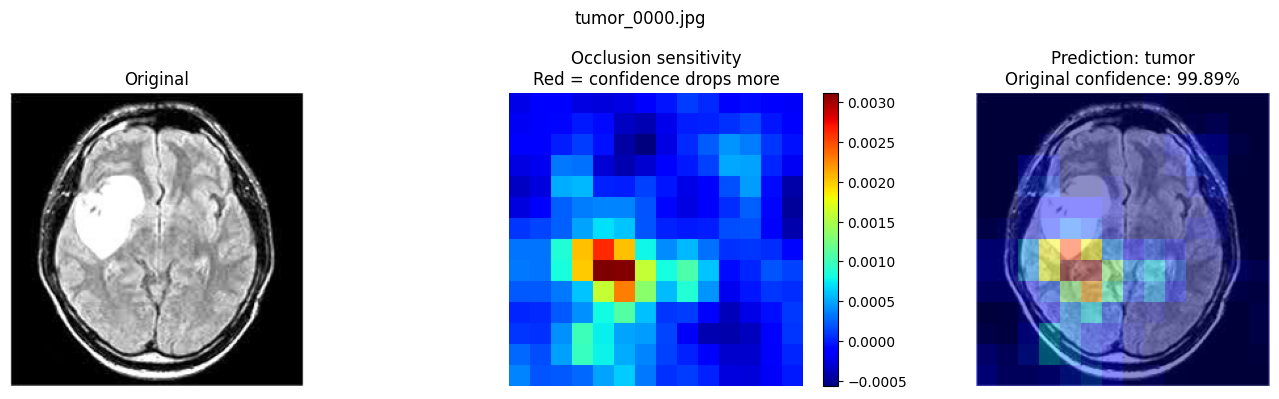

In [44]:
#脑肿瘤
tumor_image = next(
    (
        Path(TEST_DATA_DIR) /
        "test" /
        "tumor"
    ).glob("*")
)

tumor_result = occlusion_sensitivity(
    tumor_image,
    patch_size=32,
    stride=16
)

show_occlusion_result(
    tumor_result
)

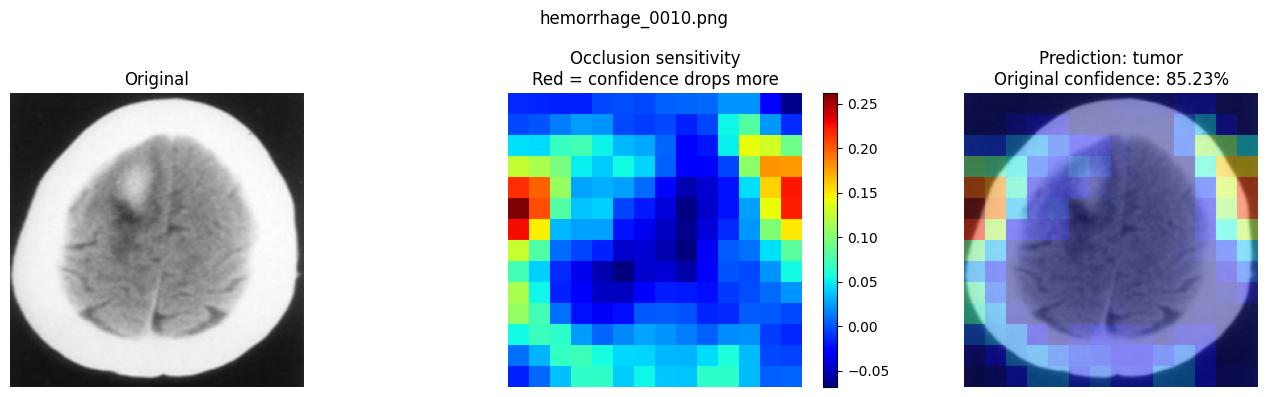

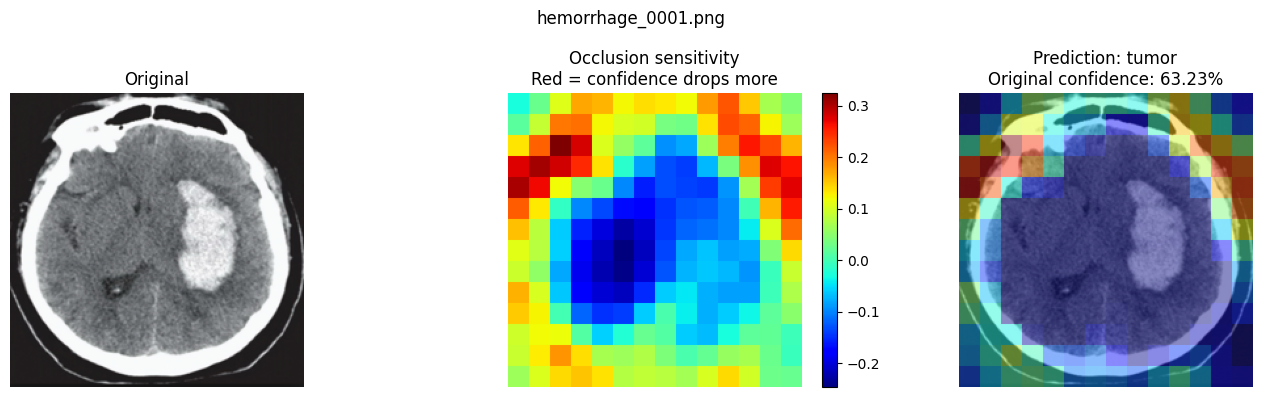

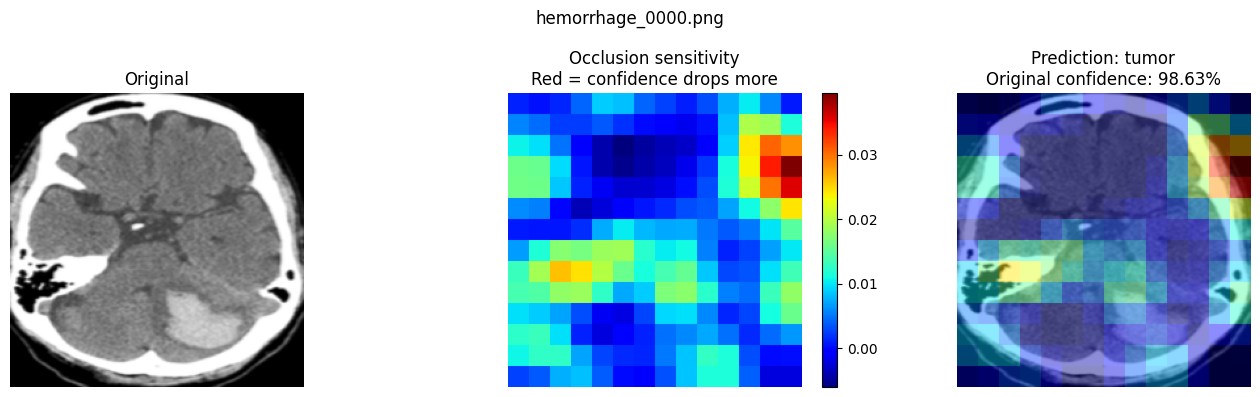

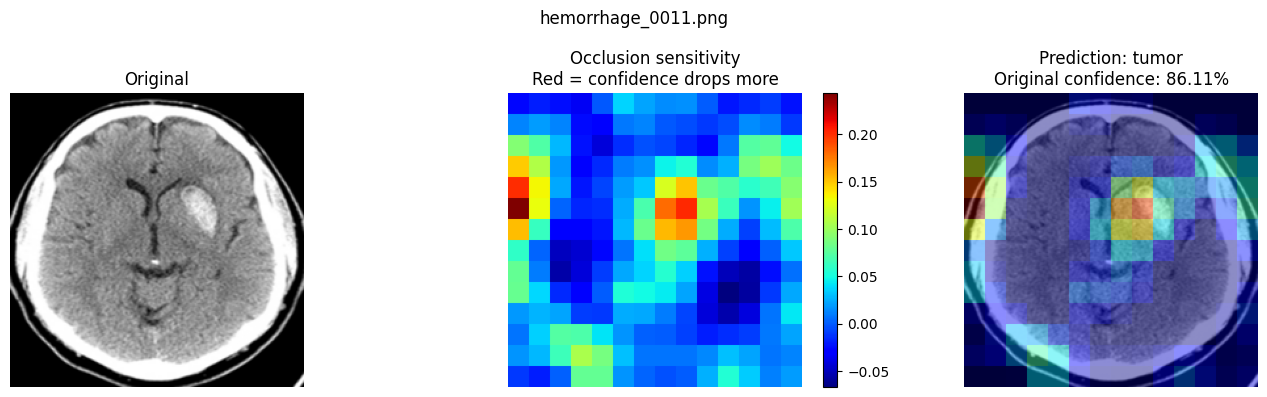

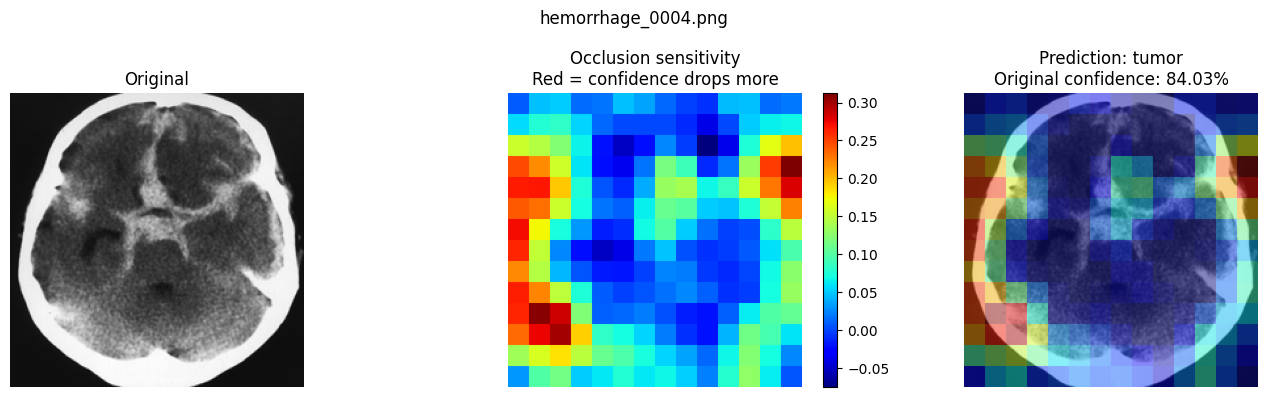

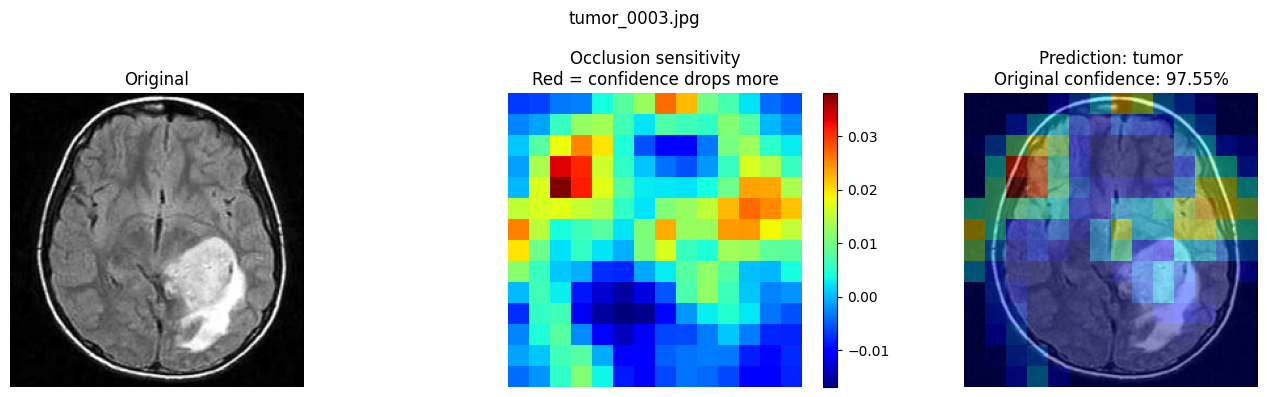

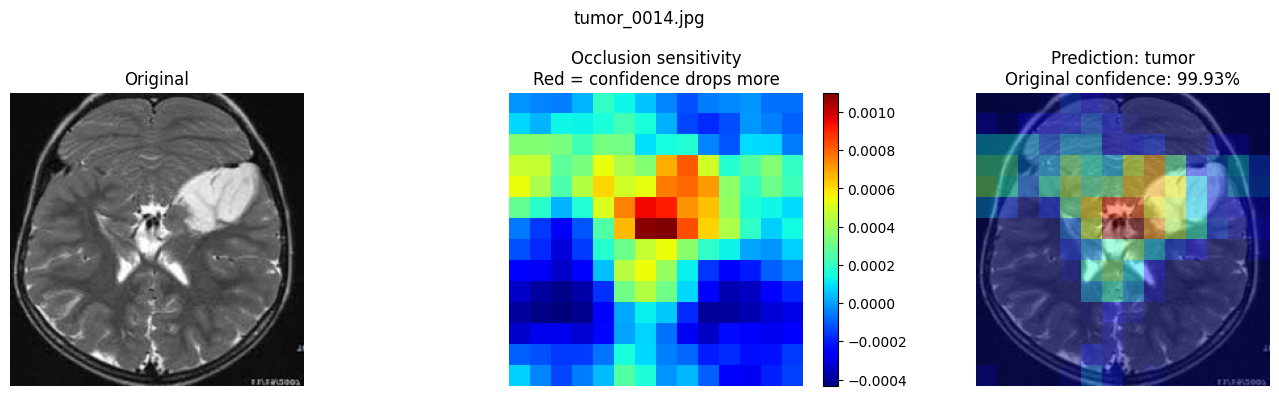

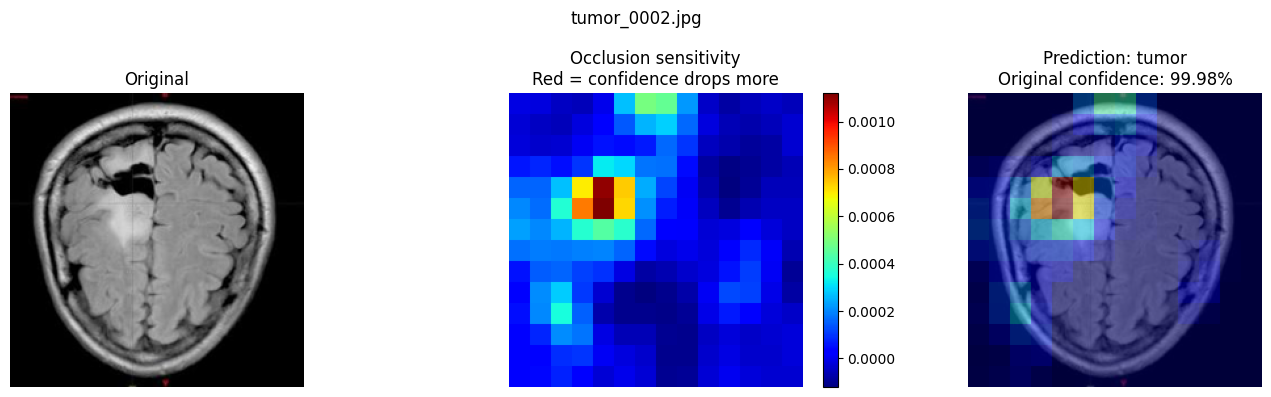

In [ ]:
import random

random.seed(42)

for true_class in (
    "hemorrhage",
    "tumor"
):
    image_files = list(
        (
            Path(TEST_DATA_DIR) /
            "test" /
            true_class
        ).glob("*")
    )

    selected_files = random.sample(
        image_files,
        min(5, len(image_files))
    )

    for image_path in selected_files:
        result = occlusion_sensitivity(
            image_path,
            patch_size=32,
            stride=16
        )

        show_occlusion_result(result)

In [4]:
from pathlib import Path
import random
import shutil
import hashlib
from collections import Counter

SEED = 42
random.seed(SEED)

# 脑出血数据
HEMORRHAGE_ROOT = Path(
    "/root/autodl-tmp/medical_data/brain_hemorrhage"
)

# 脑肿瘤 CT 原图
TUMOR_DIR = Path(
    "/root/autodl-tmp/medical_data/"
    "CTBrain-TumorSegmentation-AnnotationProject-main/"
    "raw__data/50_ct_brain_raw_data_png"
)

# 使用新目录，避免覆盖以前的数据
OUTPUT_ROOT = Path(
    "/root/autodl-tmp/medical_data/"
    "hemorrhage_vs_tumor_ct_balanced_seed42"
)

IMAGE_SUFFIXES = {".png", ".jpg", ".jpeg", ".bmp"}

split_counts = {
    "train": 35,
    "val": 7,
    "test": 8
}

print("=" * 65)
print("脑出血 CT vs 脑肿瘤 CT：数据集构建")
print("=" * 65)
print("随机种子：", SEED)
print("输出目录：", OUTPUT_ROOT)
print("划分方案：", split_counts)
print("=" * 65)

脑出血 CT vs 脑肿瘤 CT：数据集构建
随机种子： 42
输出目录： /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_ct_balanced_seed42
划分方案： {'train': 35, 'val': 7, 'test': 8}


In [5]:
# 为避免意外混入 negative，只读取 positive 目录
hemorrhage_by_split = {}

for split in ("train", "val", "test"):
    positive_dir = HEMORRHAGE_ROOT / split / "positive"

    files = sorted([
        p for p in positive_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES
    ])

    hemorrhage_by_split[split] = files

    print(
        f"{split:5s} 脑出血阳性原图："
        f"{len(files)} 张"
    )

tumor_files = sorted([
    p for p in TUMOR_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES
])

print(f"脑肿瘤 CT 原图：{len(tumor_files)} 张")

assert len(hemorrhage_by_split["train"]) >= 35
assert len(hemorrhage_by_split["val"]) >= 7
assert len(hemorrhage_by_split["test"]) >= 8
assert len(tumor_files) == 50

print("\n数量检查通过。")

train 脑出血阳性原图：70 张
val   脑出血阳性原图：15 张
test  脑出血阳性原图：15 张
脑肿瘤 CT 原图：50 张

数量检查通过。


In [7]:
from pathlib import Path
import random
import shutil

SEED = 42
IMAGE_SUFFIXES = {".png", ".jpg", ".jpeg", ".bmp"}

HEMORRHAGE_ROOT = Path(
    "/root/autodl-tmp/medical_data/brain_hemorrhage"
)

TUMOR_DIR = Path(
    "/root/autodl-tmp/medical_data/"
    "CTBrain-TumorSegmentation-AnnotationProject-main/"
    "raw__data/50_ct_brain_raw_data_png"
)

OUTPUT_ROOT = Path(
    "/root/autodl-tmp/medical_data/"
    "hemorrhage_vs_tumor_ct_balanced_seed42"
)

split_counts = {
    "train": 35,
    "val": 7,
    "test": 8
}

print("=" * 65)
print("创建脑出血 CT vs 脑肿瘤 CT 数据集")
print("=" * 65)

# 1. 创建全部目标目录
for split in ("train", "val", "test"):
    for class_name in ("hemorrhage", "tumor"):
        folder = OUTPUT_ROOT / split / class_name
        folder.mkdir(parents=True, exist_ok=True)
        print("已确认目录：", folder)

# 2. 从原数据读取脑出血阳性图片
hemorrhage_by_split = {}

for split in ("train", "val", "test"):
    source_dir = HEMORRHAGE_ROOT / split / "positive"

    files = sorted([
        p for p in source_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES
    ])

    required = split_counts[split]

    if len(files) < required:
        raise ValueError(
            f"{split} 脑出血阳性图片不足："
            f"需要 {required}，实际 {len(files)}"
        )

    rng = random.Random(SEED + ["train", "val", "test"].index(split))

    hemorrhage_by_split[split] = rng.sample(
        files,
        required
    )

# 3. 读取并划分50张脑肿瘤CT
tumor_files = sorted([
    p for p in TUMOR_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES
])

if len(tumor_files) != 50:
    raise ValueError(
        f"预期50张脑肿瘤CT，实际找到 {len(tumor_files)} 张"
    )

random.Random(SEED).shuffle(tumor_files)

tumor_by_split = {
    "train": tumor_files[:35],
    "val": tumor_files[35:42],
    "test": tumor_files[42:50]
}

# 4. 复制脑出血图片
for split, files in hemorrhage_by_split.items():
    destination = OUTPUT_ROOT / split / "hemorrhage"

    for index, source in enumerate(files):
        target = destination / (
            f"hemorrhage_{index:03d}{source.suffix.lower()}"
        )
        shutil.copy2(source, target)

# 5. 复制脑肿瘤图片
for split, files in tumor_by_split.items():
    destination = OUTPUT_ROOT / split / "tumor"

    for index, source in enumerate(files):
        target = destination / (
            f"tumor_{index:03d}{source.suffix.lower()}"
        )
        shutil.copy2(source, target)

print("=" * 65)
print("数据集生成完成")
print("位置：", OUTPUT_ROOT)
print("=" * 65)

创建脑出血 CT vs 脑肿瘤 CT 数据集
已确认目录： /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_ct_balanced_seed42/train/hemorrhage
已确认目录： /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_ct_balanced_seed42/train/tumor
已确认目录： /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_ct_balanced_seed42/val/hemorrhage
已确认目录： /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_ct_balanced_seed42/val/tumor
已确认目录： /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_ct_balanced_seed42/test/hemorrhage
已确认目录： /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_ct_balanced_seed42/test/tumor
数据集生成完成
位置： /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_ct_balanced_seed42


In [8]:
print("=" * 65)
print("最终数据分布")
print("=" * 65)

total = 0

for split in ("train", "val", "test"):
    for class_name in ("hemorrhage", "tumor"):
        folder = OUTPUT_ROOT / split / class_name

        count = len([
            p for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES
        ])

        total += count
        print(f"{split:5s} / {class_name:10s}: {count:2d}")

print("-" * 65)
print("总图片数：", total)

最终数据分布
train / hemorrhage: 35
train / tumor     : 35
val   / hemorrhage:  7
val   / tumor     :  7
test  / hemorrhage:  8
test  / tumor     :  8
-----------------------------------------------------------------
总图片数： 100


In [9]:
def file_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()


hash_locations = {}

for split in ("train", "val", "test"):
    for class_name in ("hemorrhage", "tumor"):
        folder = OUTPUT_ROOT / split / class_name

        for path in folder.iterdir():
            if path.suffix.lower() not in IMAGE_SUFFIXES:
                continue

            file_hash = file_sha256(path)

            hash_locations.setdefault(
                file_hash, []
            ).append(
                f"{split}/{class_name}/{path.name}"
            )

duplicates = {
    key: value
    for key, value in hash_locations.items()
    if len(value) > 1
}

print("跨目录完全重复的图片组数：", len(duplicates))

for locations in duplicates.values():
    print(locations)

跨目录完全重复的图片组数： 0


In [2]:
import os
import sys
import re
import subprocess
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

PROJECT_DIR = "/root/autodl-tmp/train"
DATA_DIR = "/root/autodl-tmp/medical_data/hemorrhage_vs_tumor_ct_balanced_seed42"

TEST_DATA_DIR = DATA_DIR


DATASET_NAME = "HemorrhageVsTumorCT"
NUM_CLASSES = 2

EPOCHS = 30
BATCH_SIZE = 16
N_FEATURE = BATCH_SIZE
GPU = 0

# StableNet开启
EPOCHP = 0

SEEDS = [1, 3, 7, 21, 42]

os.chdir(PROJECT_DIR)

In [3]:
all_seed_results = []
all_seed_outputs = {}

for run_index, seed in enumerate(SEEDS, start=1):
    log_base = (
        f"/root/autodl-tmp/train/"
        f"results_5seeds/seed_{seed}"
    )

    cmd = [
        sys.executable,
        "-u",
        "main_stablenet.py",
    
        "-data", DATA_DIR,
        "--dataset", DATASET_NAME,
        "--classes_num", str(NUM_CLASSES),
    
        "--gpu", str(GPU),
        "--batch-size", str(BATCH_SIZE),
        "--n_feature", str(N_FEATURE),
        "--workers", "4",
    
        "--epochs", str(EPOCHS),
        "--epochp", str(EPOCHP),
    
        "--lr", "0.001",
        "--wd", "0.0001",
        "--cos", "1",
    
        "--lrbl", "1",
        "--lambdap", "70",
        "--epochb", "20",
    
        "--seed", str(seed),
        "--log_base", log_base,
    ]

    print()
    print("=" * 65)
    print(f"第 {run_index}/{len(SEEDS)} 次实验，随机种子：{seed}")
    print("=" * 65)

    process = subprocess.Popen(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    lines = []
    evaluation_index = 0

    for line in process.stdout:
        lines.append(line)
        stripped = line.strip()

        if "* Acc@1" in line:
            epoch = evaluation_index // 2 + 1
            phase = (
                "Validation"
                if evaluation_index % 2 == 0
                else "Test"
            )

            print(
                f"Seed {seed:2d} | "
                f"Epoch {epoch:02d} | "
                f"{phase:10s} | {stripped}"
            )

            evaluation_index += 1

    process.wait()
    raw_output = "".join(lines)
    all_seed_outputs[seed] = raw_output

    if process.returncode != 0:
        print(f"\nSeed {seed} 训练失败")

        for line in lines[-60:]:
            print(line, end="")

        continue

    # 同时兼容Acc@2和Acc@5
    matches = re.findall(
        r"\*\s+Acc@1\s+([-\d.]+)"
        r"\s+Acc@(?:2|5)\s+([-\d.]+)",
        raw_output
    )

    epoch_results = []

    for i in range(0, len(matches), 2):
        if i + 1 >= len(matches):
            break

        val_accuracy = float(matches[i][0])
        test_accuracy = float(matches[i + 1][0])

        epoch_results.append({
            "epoch": i // 2 + 1,
            "val_accuracy": val_accuracy,
            "test_accuracy": test_accuracy,
        })

    if not epoch_results:
        print("没有解析到准确率")
        continue

    # 只能根据验证集选择最佳epoch
    best = max(
        epoch_results,
        key=lambda item: item["val_accuracy"]
    )

    model_path = (
        Path(log_base) /
        DATASET_NAME /
        "model_best.pth.tar"
    )

    all_seed_results.append({
        "Seed": seed,
        "Best Epoch": best["epoch"],
        "Validation Accuracy": best["val_accuracy"],
        "Test Accuracy": best["test_accuracy"],
        "Model Path": str(model_path),
        "Model Exists": model_path.is_file(),
    })

    print(
        f"\nSeed {seed} 完成："
        f"最佳epoch={best['epoch']}，"
        f"验证={best['val_accuracy']:.2f}%，"
        f"测试={best['test_accuracy']:.2f}%"
    )


第 1/5 次实验，随机种子：1
Seed  1 | Epoch 01 | Validation | * Acc@1 50.000 Acc@5 100.000
Seed  1 | Epoch 01 | Test       | * Acc@1 56.250 Acc@5 100.000
Seed  1 | Epoch 02 | Validation | * Acc@1 64.286 Acc@5 100.000
Seed  1 | Epoch 02 | Test       | * Acc@1 62.500 Acc@5 100.000
Seed  1 | Epoch 03 | Validation | * Acc@1 50.000 Acc@5 100.000
Seed  1 | Epoch 03 | Test       | * Acc@1 50.000 Acc@5 100.000
Seed  1 | Epoch 04 | Validation | * Acc@1 78.571 Acc@5 100.000
Seed  1 | Epoch 04 | Test       | * Acc@1 56.250 Acc@5 100.000
Seed  1 | Epoch 05 | Validation | * Acc@1 57.143 Acc@5 100.000
Seed  1 | Epoch 05 | Test       | * Acc@1 68.750 Acc@5 100.000
Seed  1 | Epoch 06 | Validation | * Acc@1 50.000 Acc@5 100.000
Seed  1 | Epoch 06 | Test       | * Acc@1 68.750 Acc@5 100.000
Seed  1 | Epoch 07 | Validation | * Acc@1 92.857 Acc@5 100.000
Seed  1 | Epoch 07 | Test       | * Acc@1 75.000 Acc@5 100.000
Seed  1 | Epoch 08 | Validation | * Acc@1 92.857 Acc@5 100.000
Seed  1 | Epoch 08 | Test       | * A

In [6]:
seed_df = pd.DataFrame(all_seed_results)

display(
    seed_df.style.format({
        "Validation Accuracy": "{:.2f}%",
        "Test Accuracy": "{:.2f}%"
    })
)

,Seed,Best Epoch,Validation Accuracy,Test Accuracy,Model Path,Model Exists
0,1,12,100.00%,93.75%,/root/autodl-tmp/train/results_5seeds/seed_1/HemorrhageVsTumorCT/model_best.pth.tar,True
1,3,15,100.00%,93.75%,/root/autodl-tmp/train/results_5seeds/seed_3/HemorrhageVsTumorCT/model_best.pth.tar,True
2,7,8,92.86%,75.00%,/root/autodl-tmp/train/results_5seeds/seed_7/HemorrhageVsTumorCT/model_best.pth.tar,True
3,21,19,100.00%,93.75%,/root/autodl-tmp/train/results_5seeds/seed_21/HemorrhageVsTumorCT/model_best.pth.tar,True
4,42,13,100.00%,93.75%,/root/autodl-tmp/train/results_5seeds/seed_42/HemorrhageVsTumorCT/model_best.pth.tar,True


In [8]:
from pathlib import Path

# 选择一个已经训练完成的随机种子
SELECTED_SEED = 21

BEST_MODEL = Path(
    f"/root/autodl-tmp/train/"
    f"results_5seeds/seed_{SELECTED_SEED}/"
    f"HemorrhageVsTumorCT/"
    f"model_best.pth.tar"
)

print("=" * 65)
print("Grad-CAM模型检查")
print("=" * 65)
print("随机种子：", SELECTED_SEED)
print("模型路径：", BEST_MODEL)
print("模型存在：", BEST_MODEL.is_file())
print("=" * 65)

if not BEST_MODEL.is_file():
    raise FileNotFoundError(
        f"没有找到模型：\n{BEST_MODEL}"
    )

Grad-CAM模型检查
随机种子： 21
模型路径： /root/autodl-tmp/train/results_5seeds/seed_21/HemorrhageVsTumorCT/model_best.pth.tar
模型存在： True


In [24]:
import os
import sys
import re
import torch
import torch.nn as nn

from pathlib import Path
from types import SimpleNamespace


# =========================================================
# 1. 基本配置
# =========================================================

PROJECT_DIR = "/root/autodl-tmp/train"

os.chdir(PROJECT_DIR)

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

import models


device = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)


# =========================================================
# 2. 检查当前选择的模型文件
# =========================================================

best_model_path = Path(BEST_MODEL)

if not best_model_path.is_file():
    raise FileNotFoundError(
        f"找不到模型文件：{best_model_path}"
    )

# 从路径中提取随机种子
seed_match = re.search(
    r"seed_(\d+)",
    str(best_model_path)
)

loaded_seed = (
    int(seed_match.group(1))
    if seed_match
    else None
)

# 模型路径的父目录通常就是实验名称
loaded_dataset_name = (
    best_model_path.parent.name
)


# =========================================================
# 3. 根据当前实验创建模型结构
# =========================================================

model_args = SimpleNamespace(
    n_feature=N_FEATURE,
    feature_dim=512,
    n_levels=1
)

model = models.resnet18_with_table(
    pretrained=False,
    args=model_args
)

# 当前实验是二分类
model.fc1 = nn.Linear(
    model.fc1.in_features,
    NUM_CLASSES
)


# =========================================================
# 4. 加载checkpoint
# =========================================================

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

state_dict = checkpoint["state_dict"]

# 兼容DataParallel保存的module.前缀
if any(
    key.startswith("module.")
    for key in state_dict
):
    state_dict = {
        key.removeprefix("module."): value
        for key, value in state_dict.items()
    }

model.load_state_dict(state_dict)

model = model.to(device)
model.eval()


# =========================================================
# 5. 读取checkpoint信息
# =========================================================

loaded_epoch = checkpoint.get(
    "epoch",
    "未知"
)

loaded_arch = checkpoint.get(
    "arch",
    "resnet18_with_table"
)

saved_best_accuracy = checkpoint.get(
    "best_acc1",
    None
)

# Tensor转换成普通数字
if torch.is_tensor(saved_best_accuracy):
    saved_best_accuracy = (
        saved_best_accuracy
        .detach()
        .cpu()
        .item()
    )


# =========================================================
# 6. 从5次实验汇总表中查找对应记录
# =========================================================

reported_best_epoch = None
reported_val_accuracy = None
reported_test_accuracy = None

if (
    "seed_df" in globals()
    and loaded_seed is not None
):
    matched_rows = seed_df[
        seed_df["Seed"] == loaded_seed
    ]

    if len(matched_rows) > 0:
        row = matched_rows.iloc[0]

        reported_best_epoch = int(
            row["Best Epoch"]
        )

        reported_val_accuracy = float(
            row["Validation Accuracy"]
        )

        reported_test_accuracy = float(
            row["Test Accuracy"]
        )


# =========================================================
# 7. 输出完整说明
# =========================================================

print("=" * 70)
print(" 当前加载模型信息")
print("=" * 70)

print(f"实验名称       ：{loaded_dataset_name}")

print(
    f"随机种子       ："
    f"{loaded_seed if loaded_seed is not None else '无法从路径识别'}"
)

print(f"模型结构       ：{loaded_arch}")
print(f"分类类别数     ：{NUM_CLASSES}")
print(f"Feature buffer ：{N_FEATURE}")
print(f"运行设备       ：{device}")
print("-" * 70)

print(f"模型文件       ：{best_model_path}")
print(f"实际加载epoch  ：{loaded_epoch}")

if saved_best_accuracy is not None:
    print(
        f"checkpoint记录："
        f"best_acc1={saved_best_accuracy:.2f}%"
    )
else:
    print("checkpoint记录：没有best_acc1字段")

if reported_best_epoch is not None:
    print("-" * 70)
    print("5次实验汇总表中的对应记录：")
    print(f"表格最佳epoch  ：{reported_best_epoch}")
    print(
        f"表格验证准确率 ："
        f"{reported_val_accuracy:.2f}%"
    )
    print(
        f"表格测试准确率 ："
        f"{reported_test_accuracy:.2f}%"
    )

    if int(loaded_epoch) == reported_best_epoch:
        print("一致性检查     ：✓ 当前模型就是表格中的最佳epoch")
    else:
        print(
            "一致性检查     ：⚠ 当前checkpoint与"
            "表格最佳epoch不一致"
        )
        print(
            f"                 当前加载epoch={loaded_epoch}，"
            f"表格最佳epoch={reported_best_epoch}"
        )

print("-" * 70)

print(f"训练/验证数据  ：{DATA_DIR}")

if "TEST_DATA_DIR" in globals():
    print(f"测试数据       ：{TEST_DATA_DIR}")

print("-" * 70)
print("模型状态       ：✓ 已加载，并已切换为评估模式")
print("后续用途       ：Grad-CAM、遮挡实验或测试集预测")
print("=" * 70)

 当前加载模型信息
实验名称       ：HemorrhageVsTumorCT
随机种子       ：21
模型结构       ：resnet18_with_table
分类类别数     ：2
Feature buffer ：16
运行设备       ：cuda:0
----------------------------------------------------------------------
模型文件       ：/root/autodl-tmp/train/results_5seeds/seed_21/HemorrhageVsTumorCT/epoch_19_checkpoint.pth.tar
实际加载epoch  ：19
checkpoint记录：best_acc1=93.75%
----------------------------------------------------------------------
5次实验汇总表中的对应记录：
表格最佳epoch  ：19
表格验证准确率 ：100.00%
表格测试准确率 ：93.75%
一致性检查     ：✓ 当前模型就是表格中的最佳epoch
----------------------------------------------------------------------
训练/验证数据  ：/root/autodl-tmp/medical_data/hemorrhage_vs_tumor_ct_balanced_seed42
测试数据       ：/root/autodl-tmp/medical_data/hemorrhage_vs_tumor_ct_balanced_seed42
----------------------------------------------------------------------
模型状态       ：✓ 已加载，并已切换为评估模式
后续用途       ：Grad-CAM、遮挡实验或测试集预测


In [23]:
model_dir = Path(BEST_MODEL).parent
target_epoch = 19

matching_models = []

for model_file in model_dir.glob(
    "epoch_*checkpoint.pth.tar"
):
    candidate = torch.load(
        model_file,
        map_location="cpu",
        weights_only=False
    )

    if candidate.get("epoch") == target_epoch:
        matching_models.append(
            model_file
        )

print(
    f"checkpoint内部epoch={target_epoch}"
    f"的模型文件："
)

for path in matching_models:
    print(path)

checkpoint内部epoch=19的模型文件：
/root/autodl-tmp/train/results_5seeds/seed_21/HemorrhageVsTumorCT/epoch_19_checkpoint.pth.tar


In [22]:
BEST_MODEL = str(
    matching_models[0]
)

In [30]:
# =========================================================
# 遮挡实验：一次性定义所有必需对象
# 前提：model、device、test_transform 已经定义
# =========================================================

from pathlib import Path
from PIL import Image

import numpy as np
import matplotlib.pyplot as plt
import torch


# 1. 类别名称
# 必须和ImageFolder的类别顺序一致
class_names = [
    "hemorrhage",
    "tumor",
]

display_names = {
    "hemorrhage": "脑出血",
    "tumor": "脑肿瘤",
}


# 兼容模型返回logits或(logits, features)
def get_logits(model_output):
    if isinstance(
        model_output,
        (tuple, list)
    ):
        return model_output[0]

    return model_output


# 2. 遮挡敏感度计算
def occlusion_sensitivity(
    image_path,
    patch_size=32,
    stride=16,
    target_class=None,
    batch_size=64
):
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(
            f"找不到图片：{image_path}"
        )

    original = Image.open(
        image_path
    ).convert("RGB")

    resized = original.resize(
        (224, 224)
    )

    input_tensor = (
        test_transform(original)
        .unsqueeze(0)
        .to(device)
    )

    model.eval()

    # 原图预测
    with torch.no_grad():
        logits = get_logits(
            model(input_tensor)
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

    predicted_class = int(
        probabilities.argmax(
            dim=1
        ).item()
    )

    if target_class is None:
        target_class = predicted_class

    baseline_probability = float(
        probabilities[
            0,
            target_class
        ].item()
    )

    _, _, height, width = input_tensor.shape

    occluded_images = []
    positions = []

    # 生成局部遮挡图片
    for y in range(
        0,
        height - patch_size + 1,
        stride
    ):
        for x in range(
            0,
            width - patch_size + 1,
            stride
        ):
            occluded = input_tensor.clone()

            occluded[
                :,
                :,
                y:y + patch_size,
                x:x + patch_size
            ] = 0.0

            occluded_images.append(
                occluded
            )

            positions.append(
                (x, y)
            )

    occluded_batch = torch.cat(
        occluded_images,
        dim=0
    )

    occluded_probabilities = []

    # 分批推理
    with torch.no_grad():
        for start in range(
            0,
            len(occluded_batch),
            batch_size
        ):
            batch = occluded_batch[
                start:start + batch_size
            ]

            logits = get_logits(
                model(batch)
            )

            probability = torch.softmax(
                logits,
                dim=1
            )[:, target_class]

            occluded_probabilities.extend(
                probability
                .detach()
                .cpu()
                .numpy()
            )

    score_map = np.zeros(
        (height, width),
        dtype=np.float32
    )

    count_map = np.zeros(
        (height, width),
        dtype=np.float32
    )

    for (x, y), probability in zip(
        positions,
        occluded_probabilities
    ):
        probability_drop = (
            baseline_probability -
            float(probability)
        )

        score_map[
            y:y + patch_size,
            x:x + patch_size
        ] += probability_drop

        count_map[
            y:y + patch_size,
            x:x + patch_size
        ] += 1

    score_map = score_map / np.maximum(
        count_map,
        1
    )

    return {
        "image": (
            np.asarray(resized)
            .astype(np.float32)
            / 255.0
        ),
        "score_map": score_map,
        "predicted_class": predicted_class,
        "target_class": target_class,
        "baseline_probability": baseline_probability,
        "image_path": image_path,
    }


# 3. 三列结果显示
def show_occlusion_result(result):
    image = result["image"]
    score_map = result["score_map"]
    image_path = Path(
        result["image_path"]
    )

    # 根据父文件夹读取真实类别
    true_class_name = (
        image_path.parent.name
    )

    predicted_class_name = class_names[
        result["predicted_class"]
    ]

    true_display = display_names.get(
        true_class_name,
        true_class_name
    )

    predicted_display = display_names.get(
        predicted_class_name,
        predicted_class_name
    )

    is_correct = (
        true_class_name
        == predicted_class_name
    )

    status_text = (
        "预测正确"
        if is_correct
        else "预测错误"
    )

    status_color = (
        "green"
        if is_correct
        else "red"
    )

    confidence = (
        result["baseline_probability"]
        * 100
    )

    # 叠加图只显示正向重要区域
    positive_scores = np.maximum(
        score_map,
        0
    )

    if positive_scores.max() > 0:
        normalized_scores = (
            positive_scores
            / positive_scores.max()
        )
    else:
        normalized_scores = (
            positive_scores
        )

    color_heatmap = plt.get_cmap(
        "jet"
    )(normalized_scores)[..., :3]

    overlay = np.clip(
        0.55 * image
        + 0.45 * color_heatmap,
        0,
        1
    )

    figure, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5),
        constrained_layout=True
    )

    # 第一列
    axes[0].imshow(image)
    axes[0].set_title(
        "原始图像\n"
        f"真实类别：{true_display}",
        fontsize=13
    )

    # 第二列
    heatmap_plot = axes[1].imshow(
        score_map,
        cmap="jet"
    )

    axes[1].set_title(
        "遮挡敏感度\n"
        "红色 = 遮挡后置信度下降更多",
        fontsize=13
    )

    figure.colorbar(
        heatmap_plot,
        ax=axes[1],
        fraction=0.046,
        pad=0.04
    )

    # 第三列
    axes[2].imshow(overlay)

    axes[2].set_title(
        "模型判断\n"
        f"真实类别：{true_display}\n"
        f"预测类别：{predicted_display}\n"
        f"置信度：{confidence:.2f}%",
        fontsize=13
    )

    axes[2].text(
        0.5,
        -0.09,
        status_text,
        transform=axes[2].transAxes,
        ha="center",
        va="top",
        fontsize=14,
        fontweight="bold",
        color=status_color
    )

    for axis in axes:
        axis.axis("off")

    figure.suptitle(
        f"文件：{image_path.name}",
        fontsize=15,
        fontweight="bold"
    )

    plt.show()


# =========================================================
# 自动检查
# =========================================================

required_names = [
    "model",
    "device",
    "test_transform",
    "class_names",
    "occlusion_sensitivity",
    "show_occlusion_result",
]

print("=" * 55)
print("遮挡实验定义检查")
print("=" * 55)

all_ready = True

for name in required_names:
    exists = name in globals()

    print(
        f"{name:26s}: "
        f"{'✓ 已定义' if exists else '✗ 未定义'}"
    )

    if not exists:
        all_ready = False

print("-" * 55)

if all_ready:
    print("✓ 所有对象准备完成，可以开始遮挡实验")
else:
    print("请先运行模型加载和test_transform单元格")

遮挡实验定义检查
model                     : ✓ 已定义
device                    : ✓ 已定义
test_transform            : ✓ 已定义
class_names               : ✓ 已定义
occlusion_sensitivity     : ✓ 已定义
show_occlusion_result     : ✓ 已定义
-------------------------------------------------------
✓ 所有对象准备完成，可以开始遮挡实验


In [31]:
import torch.nn.functional as F


def generate_gradcam(image_path, target_class=None):
    image_path = Path(image_path)

    original = Image.open(
        image_path
    ).convert("RGB")

    resized = original.resize((224, 224))

    input_tensor = (
        test_transform(original)
        .unsqueeze(0)
        .to(device)
    )

    activations = []
    gradients = []

    target_layer = model.layer4[-1]

    def forward_hook(module, inputs, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    forward_handle = target_layer.register_forward_hook(
        forward_hook
    )

    backward_handle = target_layer.register_full_backward_hook(
        backward_hook
    )

    model.zero_grad(set_to_none=True)

    logits, _ = model(input_tensor)
    probabilities = torch.softmax(logits, dim=1)

    predicted_class = int(
        probabilities.argmax(dim=1).item()
    )

    if target_class is None:
        target_class = predicted_class

    logits[0, target_class].backward()

    feature_map = activations[0]
    gradient = gradients[0]

    weights = gradient.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam = (
        weights * feature_map
    ).sum(dim=1, keepdim=True)

    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0].detach().cpu().numpy()

    cam -= cam.min()

    if cam.max() > 0:
        cam /= cam.max()

    forward_handle.remove()
    backward_handle.remove()

    return {
        "image_path": image_path,
        "image": np.asarray(resized).astype(np.float32) / 255.0,
        "heatmap": cam,
        "predicted_class": predicted_class,
        "target_class": target_class,
        "confidence": float(
            probabilities[0, predicted_class].item()
        )
    }

def show_gradcam(result):
    image = result["image"]
    heatmap = result["heatmap"]
    image_path = result["image_path"]

    true_name = image_path.parent.name

    predicted_name = class_names[
        result["predicted_class"]
    ]

    color_heatmap = plt.get_cmap("jet")(
        heatmap
    )[..., :3]

    overlay = np.clip(
        0.55 * image +
        0.45 * color_heatmap,
        0,
        1
    )

    figure, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    axes[0].imshow(image)
    axes[0].set_title(
        f"原图\n真实类别：{true_name}"
    )

    axes[1].imshow(
        heatmap,
        cmap="jet"
    )
    axes[1].set_title("Grad-CAM")

    axes[2].imshow(overlay)
    axes[2].set_title(
        f"预测：{predicted_name}\n"
        f"置信度：{result['confidence'] * 100:.2f}%"
    )

    for axis in axes:
        axis.axis("off")

    figure.suptitle(image_path.name)
    plt.tight_layout()
    plt.show()

In [32]:
required_names = [
    "model",
    "device",
    "test_transform",
    "class_names",
    "occlusion_sensitivity",
    "show_occlusion_result",
]

all_ready = True

for name in required_names:
    exists = name in globals()
    status = "✓ 已定义" if exists else "✗ 未定义"

    print(f"{name:24s}: {status}")

    if not exists:
        all_ready = False

print()
if all_ready:
    print("准备完成")
else: 
    print("请先运行缺失变量对应的单元格")

model                   : ✓ 已定义
device                  : ✓ 已定义
test_transform          : ✓ 已定义
class_names             : ✓ 已定义
occlusion_sensitivity   : ✓ 已定义
show_occlusion_result   : ✓ 已定义

准备完成


In [33]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_candidates = [
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Bold.ttc",
    "/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc",
    "/usr/share/fonts/truetype/arphic/uming.ttc",
]

chinese_font = None

for font_path in font_candidates:
    if Path(font_path).exists():
        fm.fontManager.addfont(font_path)

        chinese_font = fm.FontProperties(
            fname=font_path
        ).get_name()

        break

if chinese_font:
    plt.rcParams["font.family"] = chinese_font
    plt.rcParams["axes.unicode_minus"] = False

    print("已启用中文字体：", chinese_font)
else:
    print("当前系统没有找到中文字体")

已启用中文字体： Noto Sans CJK JP


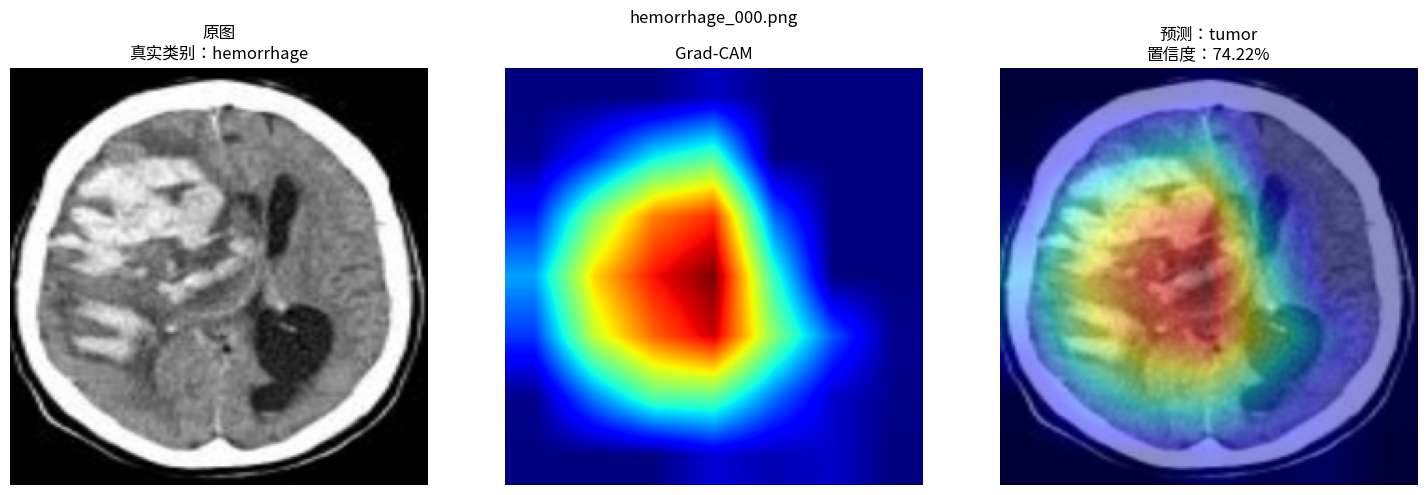

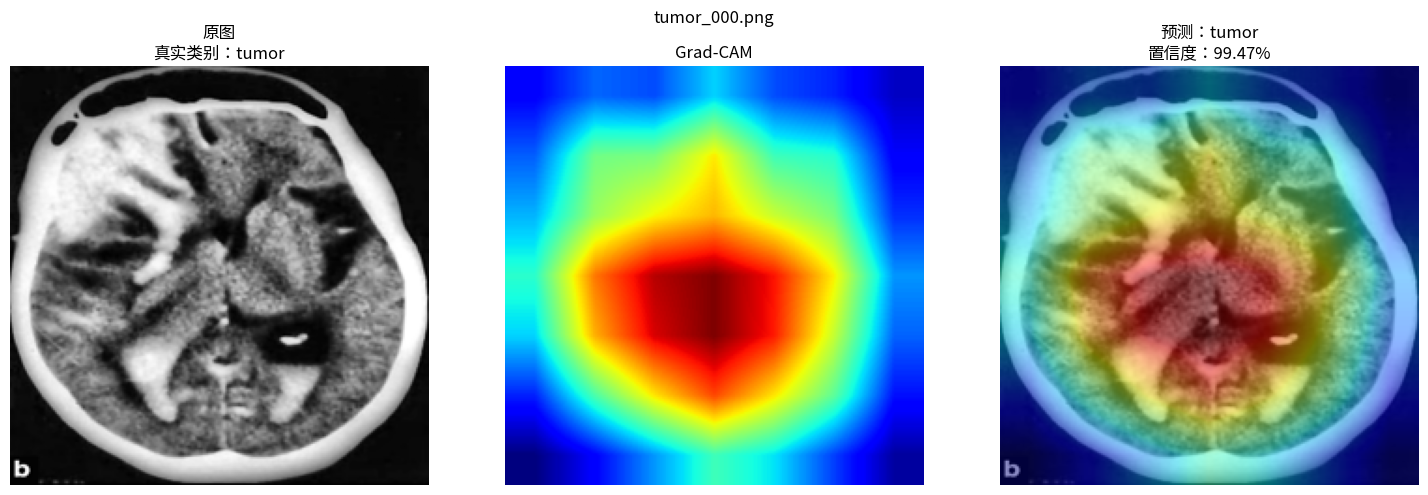

In [34]:
for class_name in ("hemorrhage", "tumor"):
    image_path = next(
        (
            Path(TEST_DATA_DIR) /
            "test" /
            class_name
        ).glob("*")
    )

    result = generate_gradcam(image_path)
    show_gradcam(result)

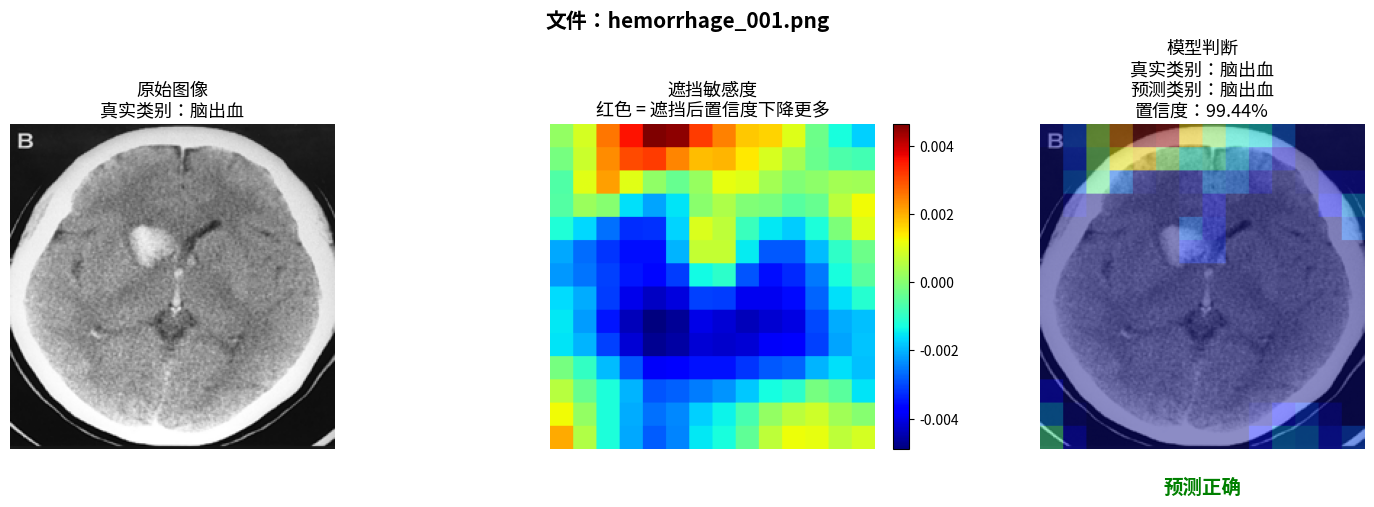

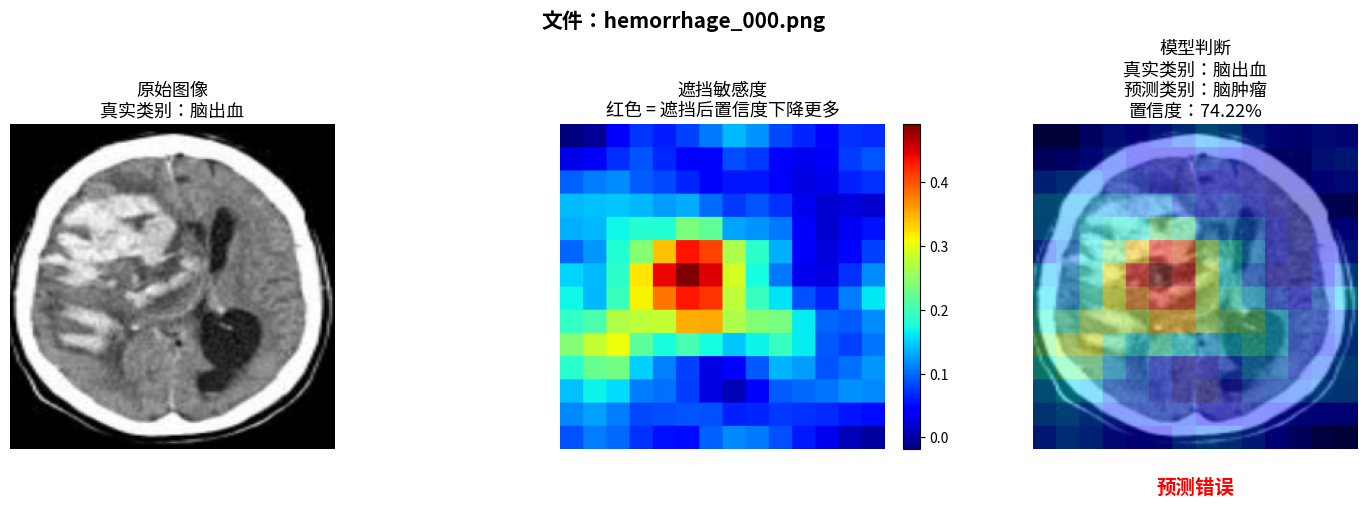

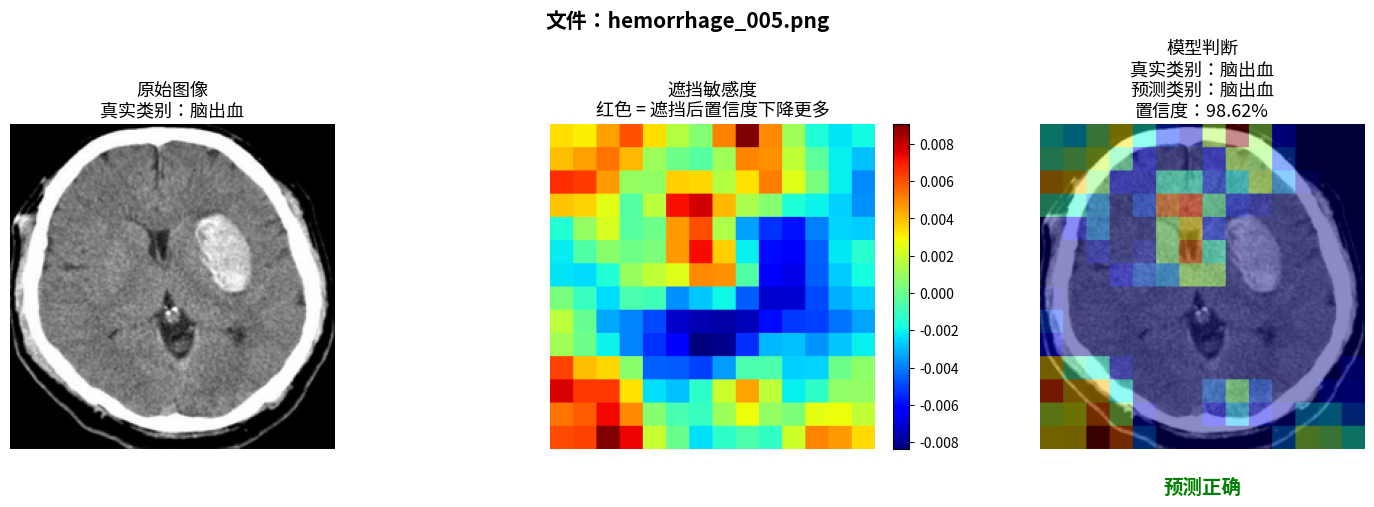

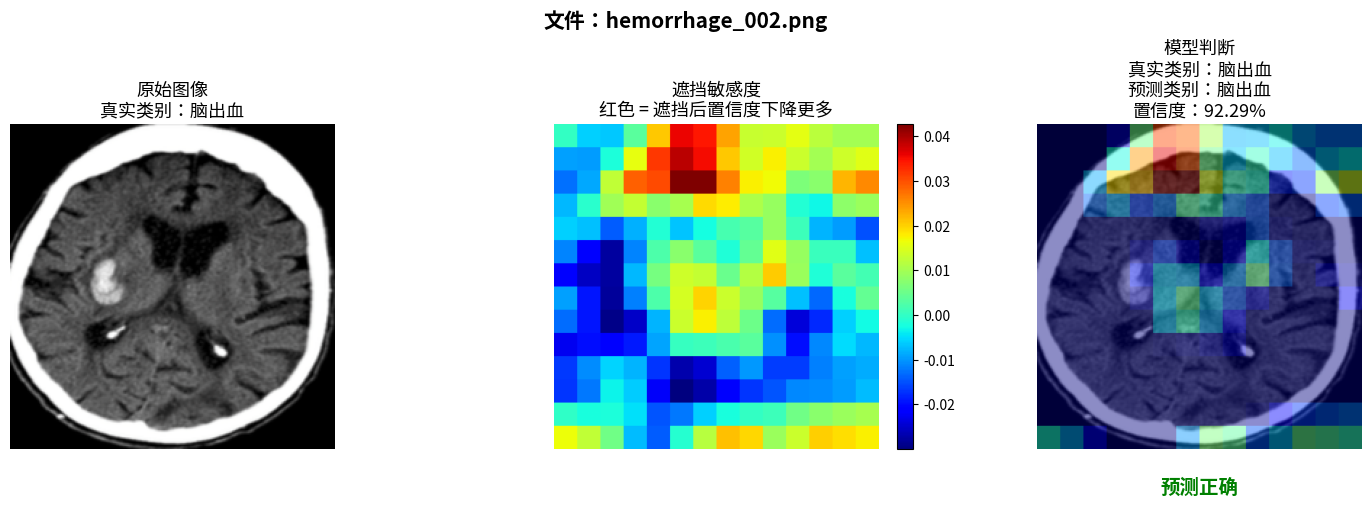

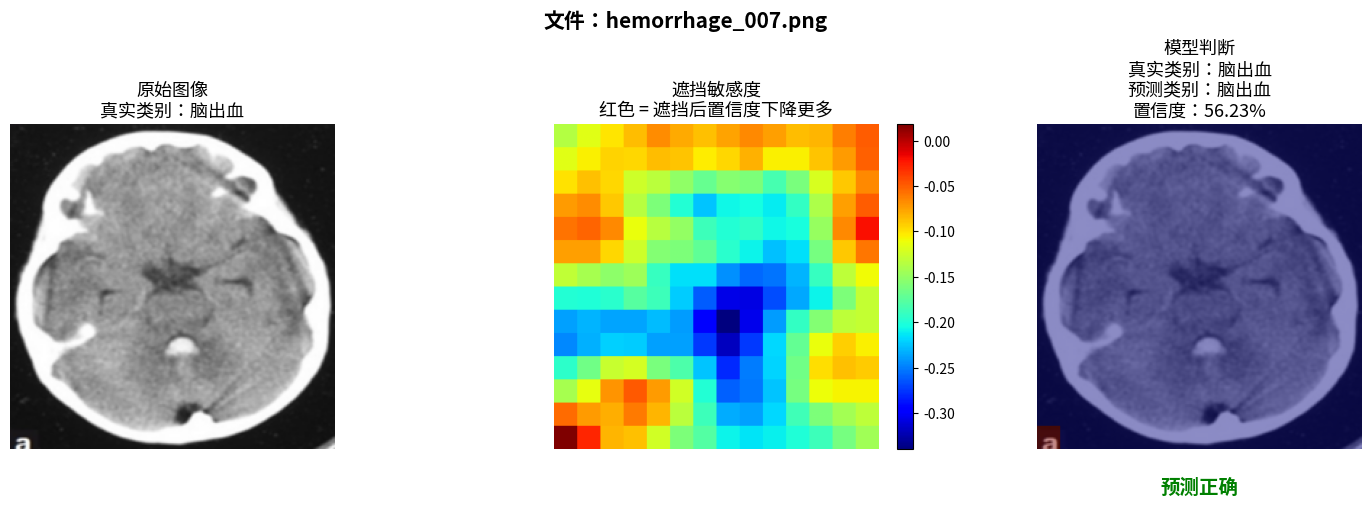

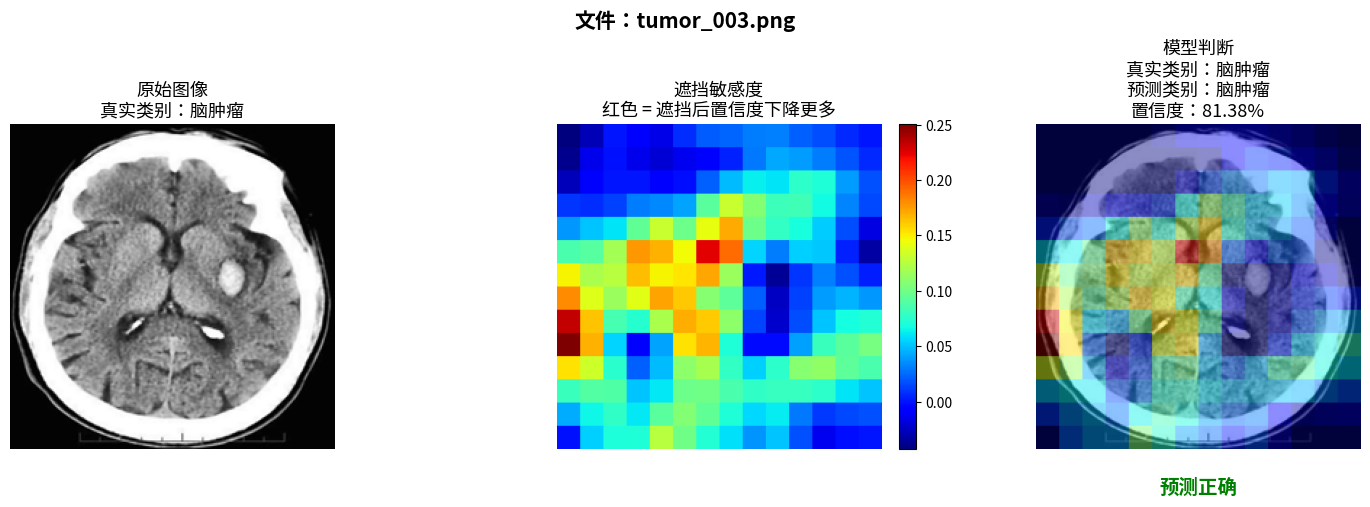

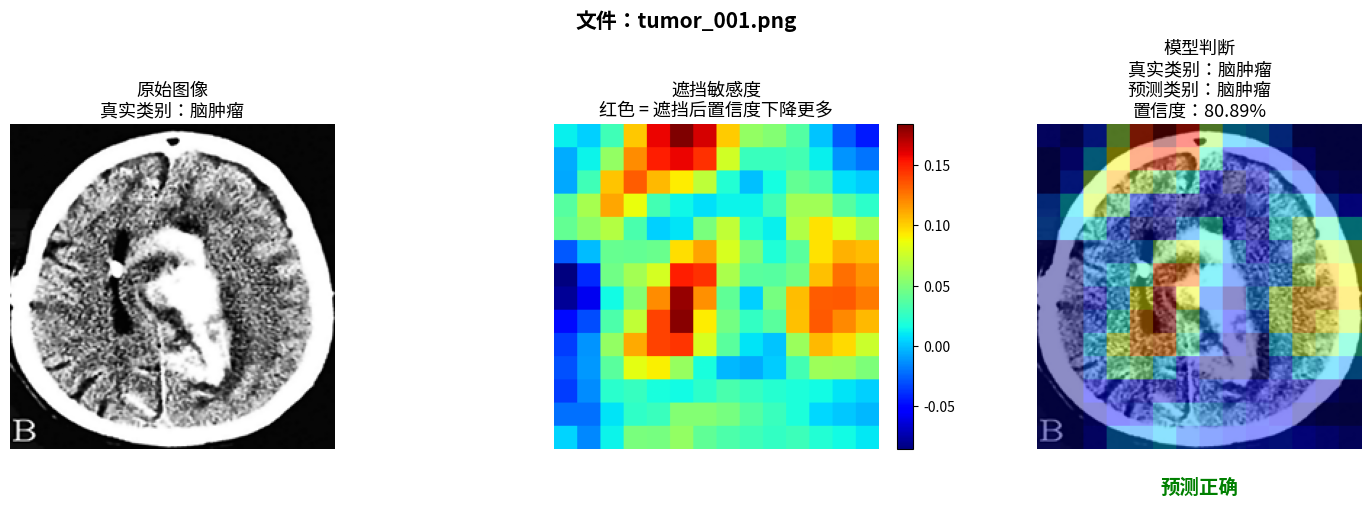

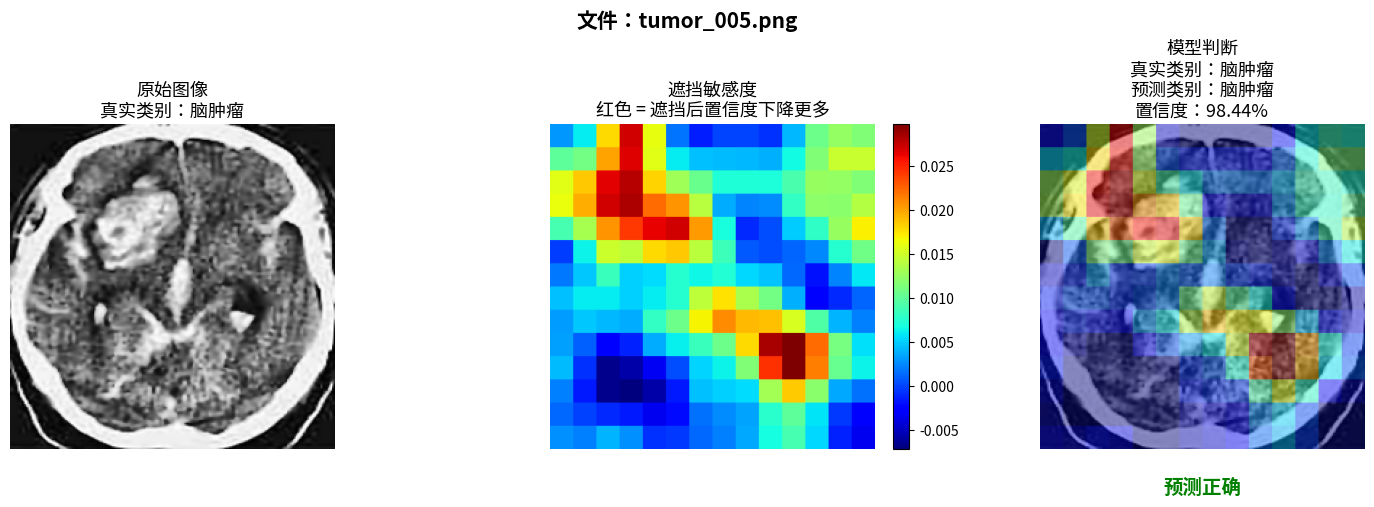

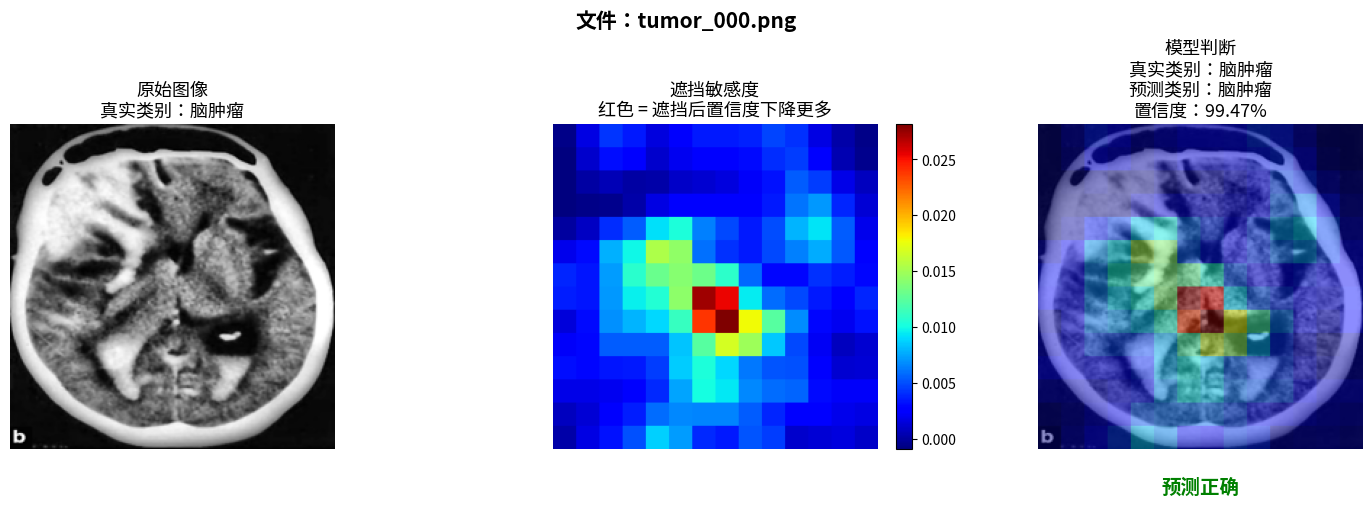

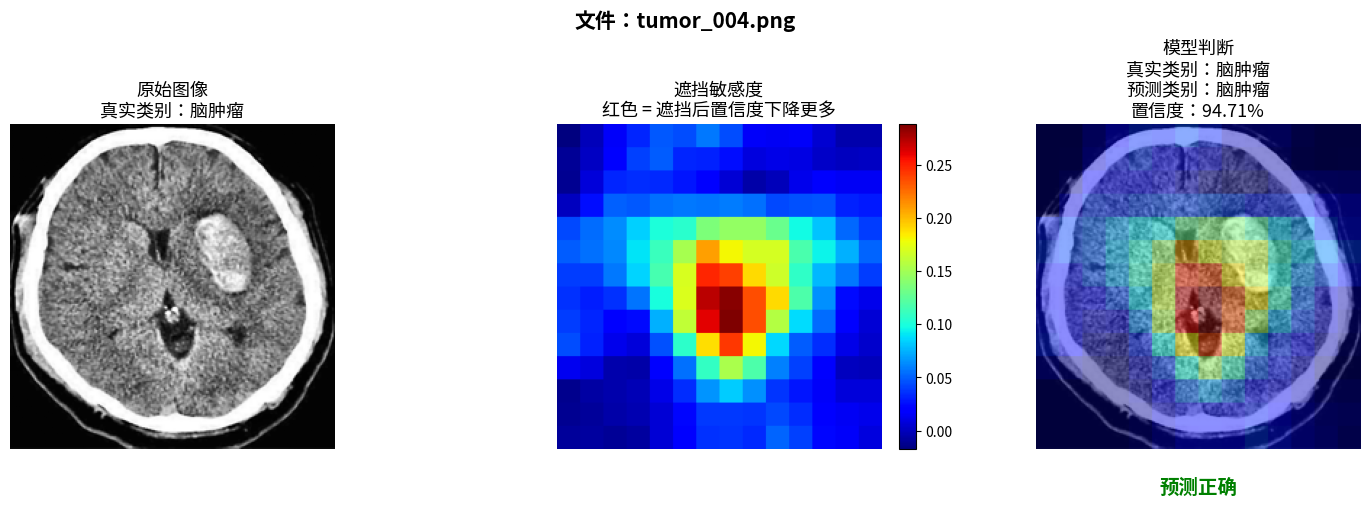

In [35]:
import random

random.seed(42)

for true_class in (
    "hemorrhage",
    "tumor"
):
    image_files = list(
        (
            Path(TEST_DATA_DIR) /
            "test" /
            true_class
        ).glob("*")
    )

    selected_files = random.sample(
        image_files,
        min(5, len(image_files))
    )

    for image_path in selected_files:
        result = occlusion_sensitivity(
            image_path,
            patch_size=32,
            stride=16
        )

        show_occlusion_result(result)